In [30]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
from skimage import img_as_ubyte
import matplotlib.pyplot as plt
import constants
import IPython.display as d
import json
import os
import time
import torch
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Variable
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import shutil
from sklearn import metrics
from PIL import Image
import json
import random
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import keras_tuner
import gc

hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [31]:
def build_model(hp):
    model = keras.models.Sequential()
    model.add(keras.Input(shape=(64,64,3)))

    for i in range(hp.Int("filter_layers", 1, 3)):
        model.add(layers.Conv2D(
            filters=hp.Int(f"filters_{i}", min_value=8, max_value=64, step=2, sampling="log"), 
            kernel_size=3, 
            activation='relu', padding="same"))
        model.add(layers.Dropout(0.3))
        model.add(layers.MaxPooling2D(pool_size=2, strides=2))

    model.add(layers.Flatten())
    for i in range(hp.Int("dense_layers", 1, 3)):
        model.add(layers.Dense(
            units=hp.Int(f"units_{i}", min_value=8, max_value=64, step=2, sampling="log"), 
            activation="relu"))

    model.add(layers.Dense(units=1, activation='sigmoid'))

    model.compile(
        loss=tf.keras.losses.binary_crossentropy,
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.binary_accuracy, keras.metrics.Recall()]
    )
    return model

In [7]:
tuner = keras_tuner.RandomSearch(
    hypermodel=build_model,
    objective=['val_binary_accuracy', keras_tuner.Objective('val_recall', direction='max')],
    max_trials=6,
    overwrite=True,
)

In [11]:
tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 4, 'step': 1, 'sampling': 'linear'}
filters_0 (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 64, 'step': 2, 'sampling': 'log'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 64, 'step': 2, 'sampling': 'log'}


In [32]:
train_ds, valid_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_rescaled_train/',
    labels='inferred',
    # label_mode='categorical',
    label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    validation_split=0.3,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_rescaled_test/',
    labels='inferred',
    # label_mode='categorical',
    label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    # shuffle=False
)


Found 8430 files belonging to 2 classes.
Found 3570 files belonging to 2 classes.


In [8]:
tuner.search(train_ds, epochs=50, validation_data=valid_ds)

Trial 6 Complete [00h 08m 11s]
multi_objective: -1.7760873436927795

Best multi_objective So Far: -1.7760873436927795
Total elapsed time: 00h 51m 27s
INFO:tensorflow:Oracle triggered exit


In [26]:
model = keras.models.Sequential()
model.add(keras.Input(shape=(64,64,3)))

model.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding="same"))
model.add(layers.Dropout(0.3))
model.add(layers.MaxPooling2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=64, kernel_size=3, activation='relu', padding="same"))
model.add(layers.Dropout(0.3))
model.add(layers.MaxPooling2D(pool_size=2, strides=2))

model.add(layers.Flatten())

model.add(layers.Dense(units=64, activation="relu"))
model.add(layers.Dense(units=8, activation="relu"))

model.add(layers.Dense(units=1, activation='sigmoid'))

model.compile(
    # loss=tf.keras.losses.categorical_crossentropy,
    loss=tf.keras.losses.binary_crossentropy,
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    # metrics=['accuracy']
    # metrics=keras.metrics.FalseNegatives()
    metrics=[keras.metrics.binary_accuracy, keras.metrics.Recall()]
    # metrics=[keras.metrics.confusion_matrix()]
)

In [46]:
origineel_model = keras.models.Sequential()
origineel_model.add(keras.Input(shape=(64,64,3)))

origineel_model.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding="same"))
origineel_model.add(layers.Dropout(0.3))
origineel_model.add(layers.MaxPooling2D(pool_size=2, strides=2))
origineel_model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding="same"))
origineel_model.add(layers.Dropout(0.3))
origineel_model.add(layers.MaxPooling2D(pool_size=2, strides=2))
origineel_model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding="same"))
origineel_model.add(layers.Dropout(0.3))
origineel_model.add(layers.MaxPooling2D(pool_size=2, strides=2))

origineel_model.add(layers.Flatten())

origineel_model.add(layers.Dense(units=64, activation="relu"))

origineel_model.add(layers.Dense(units=1, activation='sigmoid'))

origineel_model.compile(
    loss=tf.keras.losses.binary_crossentropy,
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    # metrics=['accuracy']
    # metrics=keras.metrics.FalseNegatives()
    metrics=[keras.metrics.binary_accuracy]
    # metrics=[keras.metrics.confusion_matrix()]
)

In [47]:
history = origineel_model.fit(
    train_ds, 
    epochs=50, 
    batch_size=16,
    # steps_per_epoch=100,
    validation_data=valid_ds, 
    use_multiprocessing=True)
# pos = len(os.listdir('./data/images_rescaled_train/positive/'))
# neg = len(os.listdir('./data/images_rescaled_train/negative/'))
# print(round(neg/(neg + pos),4))
# tuner.results_summary()

Epoch 1/50
527/527 [==============================] - 12s 21ms/step - loss: 2.6387 - binary_accuracy: 0.8460 - val_loss: 0.3755 - val_binary_accuracy: 0.8833
Epoch 2/50
527/527 [==============================] - 8s 15ms/step - loss: 0.2940 - binary_accuracy: 0.8759 - val_loss: 0.3672 - val_binary_accuracy: 0.8824
Epoch 3/50
527/527 [==============================] - 9s 18ms/step - loss: 0.2842 - binary_accuracy: 0.8751 - val_loss: 0.3583 - val_binary_accuracy: 0.8832
Epoch 4/50
527/527 [==============================] - 10s 18ms/step - loss: 0.2786 - binary_accuracy: 0.8809 - val_loss: 0.3580 - val_binary_accuracy: 0.8849
Epoch 5/50
527/527 [==============================] - 10s 18ms/step - loss: 0.2742 - binary_accuracy: 0.8808 - val_loss: 0.3960 - val_binary_accuracy: 0.8830
Epoch 6/50
527/527 [==============================] - 10s 18ms/step - loss: 0.2714 - binary_accuracy: 0.8815 - val_loss: 0.3375 - val_binary_accuracy: 0.8830
Epoch 7/50
527/527 [==============================] - 

In [30]:
model.save('./trained_models/model1_binacc_recall.h5')

In [39]:
origineel_model.save('./trained_models/model1_origineel.h5')

NameError: name 'origineel_model' is not defined

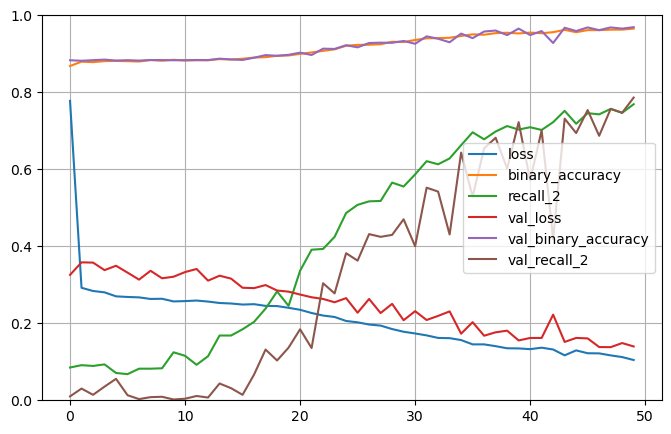

In [34]:
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.show()

In [9]:
models = tuner.get_best_models(3)
best_model1 = models[0]
best_model1.build()
best_model1.summary()
best_model2 = models[1]
best_model2.build()
best_model2.summary()
best_model3 = models[2]
best_model3.build()
best_model3.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 16)        448       
                                                                 
 dropout (Dropout)           (None, 64, 64, 16)        0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 32)        4640      
                                                                 
 dropout_1 (Dropout)         (None, 32, 32, 32)        0         
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 16, 32)       0         
 2D)                                                    

In [10]:
best_model1.evaluate(test_ds)
best_model2.evaluate(test_ds)
best_model3.evaluate(test_ds)
pos = len(os.listdir('./data/images_rescaled_test/positive/'))
neg = len(os.listdir('./data/images_rescaled_test/negative/'))
print(round(1 - pos/(neg + pos),4))

224/224 [==============================] - 2s 6ms/step - loss: 0.2806 - binary_accuracy: 0.8826 - recall: 0.0467
0.886


In [11]:
best_model1.save("./models/model1_binary_recall1.h5")
best_model2.save("./models/model1_binary_recall2.h5")
best_model3.save("./models/model1_binary_recall3.h5")

In [33]:
saved_model1 = keras.models.load_model("./models/model1_binary1.h5")
saved_model2 = keras.models.load_model("./models/model1_binary2.h5")
saved_model3 = keras.models.load_model("./models/model1_binary3.h5")
# saved_model1.evaluate(test_ds)
saved_model1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 8)         224       
                                                                 
 dropout (Dropout)           (None, 64, 64, 8)         0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 8)        0         
 )                                                               
                                                                 
 flatten (Flatten)           (None, 8192)              0         
                                                                 
 dense (Dense)               (None, 64)                524352    
                                                                 
 dense_1 (Dense)             (None, 1)                 65        
                                                        

# Testing model

In [37]:
def test_model(model, dataset):
    filtered_data = []
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for i, (images, label) in enumerate(dataset, 0):
        output = model(images)
        prediction = output.numpy()
        for i in range(len(prediction)):
            if prediction[i][0] > 0.4:
                if label[i]== 1:
                    TP += 1
                else: FP += 1
                filtered_data.append(images[i])
                # print(prediction[i], label[i])
            else:
                if label[i]== 1:
                    FN += 1
                else: TN += 1
    return filtered_data, TP, FP, TN, FN

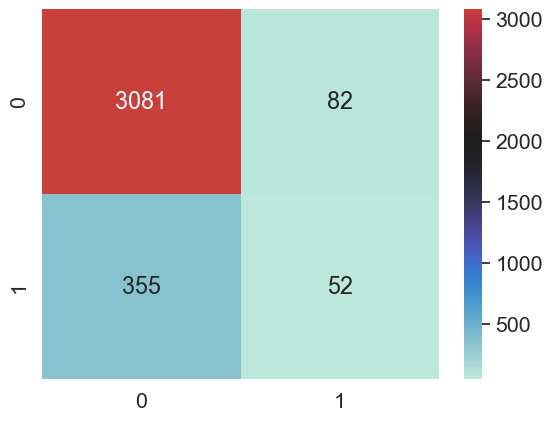

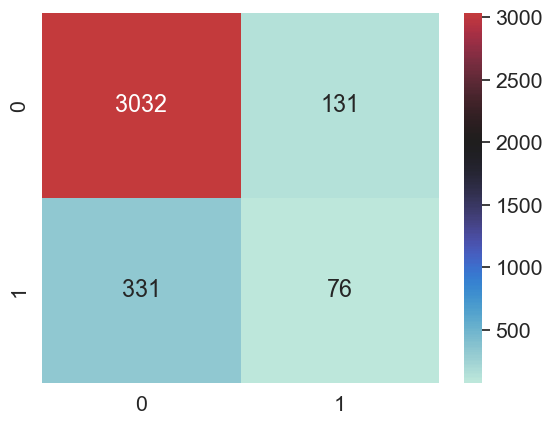

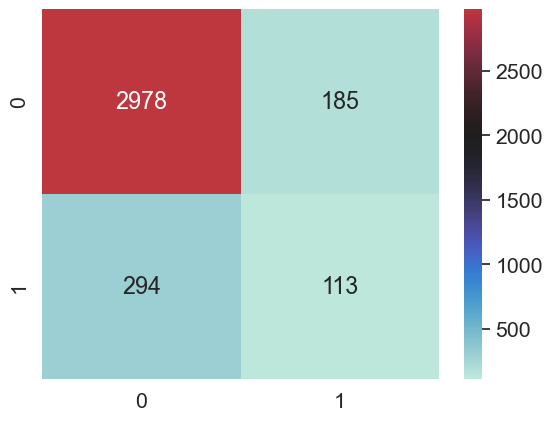

In [38]:
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
for model_test in [saved_model1, saved_model2, saved_model3]:
    filtered_data, TP, FP, TN, FN = test_model(model_test, test_ds)

    array = [[TN, FP],
            [FN, TP]]

    df_cm = pd.DataFrame(array, range(2), range(2))
    sn.heatmap(df_cm, annot=True, center=2000, fmt='g')

    plt.show()
    # print(model.summary())
    # print(TN, FN)       
    # print(FP, TP)    
    # print((TP)/(TP+0.5*(FP+FN)))
    
    # if labels_total[i][0] == 1:
    #     print(predicted_total[i], labels_total[i])
    # print("bestandsnaam: {}, voorspeld: {}\n".format(images_total[i], predicted_total[i]))
# print(i, len(filtered_data))

In [29]:
filtered_data, TP, FP, TN, FN = test_model(model, test_ds)

# print(model.summary())
print(TN, FP)       
print(FN, TP)    
print((TP)/(TP+0.5*(FP+FN)))

3036 322
127 85
0.27463651050080773


In [35]:
filtered_data, TP, FP, TN, FN = test_model(origineel_model, test_ds)

# print(model.summary())
print(TN, FN)       
print(FP, TP)    
print((TP)/(TP+0.5*(FP+FN)))

3005 274
158 133
0.38108882521489973


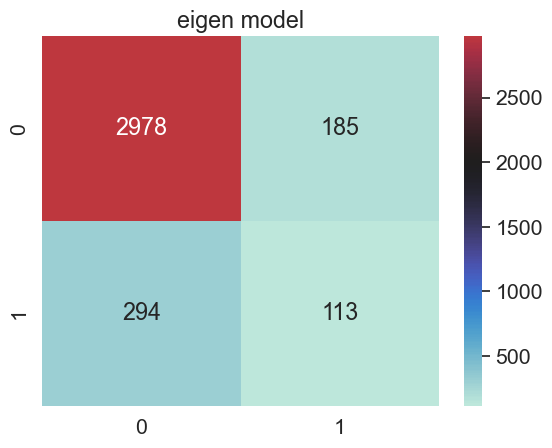

In [54]:
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

filtered_data, TP, FP, TN, FN = test_model(saved_model3, test_ds)

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=2000, fmt='g')
plt.title('eigen model')

plt.show()

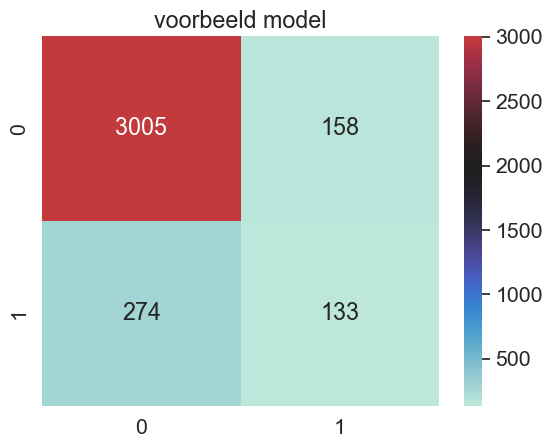

In [55]:
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

origineel = keras.models.load_model('./trained_models/model1_origineel.h5')

# for model_test in [saved_model3, origineel]:
filtered_data, TP, FP, TN, FN = test_model(origineel, test_ds)

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=2000, fmt='g')
plt.title('voorbeeld model')
plt.show()

In [66]:
saved_model3.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 8)         224       
                                                                 
 dropout (Dropout)           (None, 64, 64, 8)         0         
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 8)        0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        4672      
                                                                 
 dropout_1 (Dropout)         (None, 32, 32, 64)        0         
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 16, 64)       0         
 2D)                                                    